# Patstāvīgais darbs · Pandas · Gaisa izplešanās sildīšanas laikā

Rūpnīcā pārbauda gaisa izplešanos cilindrā ar kustīgu virzuli. Gaisa masa un spiediens ir nemainīgi. Katru minūti reģistrē temperatūru un tilpumu. Sildīšanas ātrums mainās, tāpēc vienādos laika intervālos temperatūra pieaug par atšķirīgu grādu skaitu. Dati ir simulēti.

**Izpētes jautājums.** Kā mainās gaisa blīvums, pieaugot temperatūrai?

Izpildi šūnas secīgi un papildini tās, kurās ir komentārs ar uzdevumu.

In [1]:
import requests
import pandas as pd

### 1. Iegūsti datus no servera

Izmanto zemāk doto adresi. Ar `requests.get(url, timeout=30)` nosūti pieprasījumu un saglabā atbildi mainīgajā `atbilde`. Izsauc `atbilde.raise_for_status()`, lai pamanītu servera kļūdu. Ar `atbilde.json()` iegūsti Python vārdnīcu un saglabā to mainīgajā `dati`.

In [2]:
url = "https://github.com/okskola/matinz/raw/refs/heads/main/W4/gaisa_sildisana.json"

atbilde = requests.get(url, timeout=30)
atbilde.raise_for_status()
dati = atbilde.json()

### 2. Izveido mērījumu tabulu

JSON ārējais objekts ir vārdnīca. `dati["mass_g"]` ir viena masa gramos visam eksperimentam. `dati["measurements"]` ir saraksts, kurā katra vārdnīca apraksta vienu mērījumu. Izpildi piemēru. Ko nozīmē viena tabulas rinda?

In [3]:
masa_g = dati["mass_g"]
df = pd.DataFrame(dati["measurements"])
df.head()

,time_s,temperature_C,volume_cm3
0,0,20,1000.0
1,60,21,1003.4
2,120,23,1010.2
3,180,26,1020.5
4,240,30,1034.1


### 3. Aprēķini blīvumu katrā mērījumā

Blīvumu iegūst, dalot masu ar tilpumu. Izveido kolonnu `density_g_cm3`: dali `masa_g` ar kolonnas `volume_cm3` vērtībām. Parādi pirmās piecas tabulas rindas.

**Pašpārbaude.** Dotajā JSON paraugā pie 20 °C tilpums ir 1000,0 cm³ un masa ir 1,2 g. Šai rindai jāiegūst 0,0012 g/cm³.

In [4]:
df["density_g_cm3"] = masa_g / df["volume_cm3"]
df.head()

,time_s,temperature_C,volume_cm3,density_g_cm3
0,0,20,1000.0,0.001200
1,60,21,1003.4,0.001196
2,120,23,1010.2,0.001188
3,180,26,1020.5,0.001176
4,240,30,1034.1,0.001160


### 4. Uzzīmē blīvuma atkarību no temperatūras

Izmanto `df.plot(...)`. Ar `x` norādi temperatūras kolonnu un ar `y` — aprēķinātā blīvuma kolonnu. Parametri `marker="o"` un `linestyle="None"` parāda katru mērījumu kā punktu. Ar `xlabel` un `ylabel` norādi asu nosaukumus un mērvienības: **Temperatūra (°C)** un **Blīvums (g/cm³)**.

<Axes: xlabel='Temperatūra (°C)', ylabel='Blīvums (g/cm³)'>

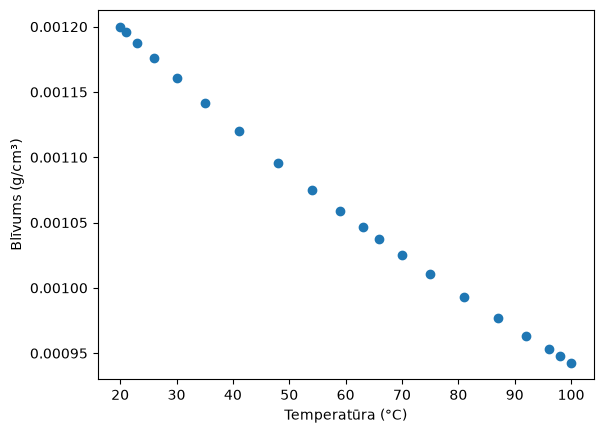

In [5]:
df.plot(
    x="temperature_C",
    y="density_g_cm3",
    marker="o",
    linestyle="None",
    xlabel="Temperatūra (°C)",
    ylabel="Blīvums (g/cm³)",
    legend=False,
)